# H2 Machine Learning Analysis

**H2: A Random Forest model provides the highest spoofing detection accuracy in IoT baggage tracking data compared to other ML models.**

**RQ2: Which ML models are most effective at detecting spoofing in Internet of Things enabled baggage tracking data?**

This notebook evaluates H2 by comparing Logistic Regression, Support Vector Machine, and Random Forest using the prepared RFID baggage tracking data.

**BLUF:** The analysis examines which of the three Machine Learning models provides the strongest spoofing detection performance.

## Step 1: Connect and Review the Prepared RFID Data

The prepared RFID baggage tracking file was connected from the Praxis project folder. The data was reviewed to confirm the number of scan records, baggage journeys, spoofed reader records, and available fields before the H2 model comparison continued.

In [2]:
# Step 1: Connect and review the prepared RFID data


# Load the library

import pandas as pd


# Connect Google Drive

from google.colab import drive

drive.mount('/content/drive')


# Set the main project folder

main_folder = "/content/drive/MyDrive/Praxis_Coding"


# Set the prepared data folder

prepared_folder = main_folder + "/06_Prepared_Data"


# Set the prepared RFID file

prepared_file = (
    prepared_folder +
    "/02_Prepared_RFID_Data.csv"
)


# Load the prepared RFID data

h2_data = pd.read_csv(prepared_file)


print("The prepared RFID data is connected.")


# Check the dataset size

print(
    "\nTotal RFID records:",
    len(h2_data)
)

print(
    "Total columns:",
    len(h2_data.columns)
)

print(
    "Total baggage journeys:",
    h2_data["bag_id"].nunique()
)

print(
    "Unique scan IDs:",
    h2_data["scan_id"].nunique()
)


# Check the spoofed reader records

print(
    "\nSpoofed Reader scans:",
    (h2_data["scan_status"] == "Spoofed Reader").sum()
)

print(
    "Spoofing label records:",
    (h2_data["spoofing_label"] == 1).sum()
)


# Check the prepared fields

print("\nPrepared RFID fields:")

print(
    h2_data.columns.tolist()
)

Mounted at /content/drive
The prepared RFID data is connected.

Total RFID records: 31575
Total columns: 34
Total baggage journeys: 5000
Unique scan IDs: 31575

Spoofed Reader scans: 375
Spoofing label records: 375

Prepared RFID fields:
['bag_id', 'tag_id', 'reader_id', 'reader_location', 'custody_point', 'timestamp', 'expected_sequence', 'actual_sequence', 'expected_next_point', 'actual_next_point', 'scan_status', 'route_type', 'transfer_status', 'journey_status', 'journey_abnormal_type', 'expected_reader_id', 'expected_reader_location', 'expected_timestamp', 'disruption_id', 'disruption_window', 'flight_id', 'route_id', 'origin', 'destination', 'scan_id', 'disruption_minutes', 'reader_match', 'location_match', 'sequence_match', 'time_difference_minutes', 'delayed_indicator', 'scan_gap_minutes', 'final_label', 'spoofing_label']


## Step 2: Review the H2 Spoofing Data

The spoofing records were reviewed before the Machine Learning data was prepared. Reader identity, expected reader identity, reader match, and the known spoofing labels were compared to determine whether any prepared field directly identifies the spoofed reader activity.

In [4]:
# Step 2: Review the H2 spoofing data


# Compare reader identity with the spoofing label

print("\nReader ID and spoofing label:")

print(
    pd.crosstab(
        h2_data["reader_id"],
        h2_data["spoofing_label"]
    )
)


# Compare reader match with the spoofing label

print("\nReader match and spoofing label:")

print(
    pd.crosstab(
        h2_data["reader_match"],
        h2_data["spoofing_label"]
    )
)


# Review the spoofed reader records

print("\nSpoofed reader records:")

print(
    h2_data.loc[
        h2_data["spoofing_label"] == 1,
        [
            "reader_id",
            "expected_reader_id",
            "reader_match",
            "scan_status"
        ]
    ]
    .value_counts()
)


Reader ID and spoofing label:
spoofing_label     0    1
reader_id                
RDR001          4948    0
RDR002          4932    0
RDR003          4958    0
RDR004          4966    0
RDR005          1489    0
RDR006          4951    0
RDR007          4956    0
RDR999             0  375

Reader match and spoofing label:
spoofing_label      0    1
reader_match              
0                   0  375
1               31200    0

Spoofed reader records:
reader_id  expected_reader_id  reader_match  scan_status   
RDR999     RDR002              0             Spoofed Reader    67
           RDR006              0             Spoofed Reader    66
           RDR001              0             Spoofed Reader    63
           RDR003              0             Spoofed Reader    60
           RDR007              0             Spoofed Reader    55
           RDR004              0             Spoofed Reader    50
           RDR005              0             Spoofed Reader    14
Name: count, dtype: 

## Step 3: Create the H2 Modeling Data

A separate working copy of the prepared RFID data was created for the H2 Machine Learning analysis. The original prepared data remained unchanged. The spoofed reader records were adjusted within the H2 working data to represent different spoofing patterns so one unique reader value would not directly identify the known spoofing outcome.

In [5]:
# Step 3: Create the H2 modeling data


# Load NumPy

import numpy as np


# Create a separate H2 working copy

h2_model_data = h2_data.copy()


# Convert the timestamp fields

h2_model_data["timestamp"] = pd.to_datetime(
    h2_model_data["timestamp"]
)

h2_model_data["expected_timestamp"] = pd.to_datetime(
    h2_model_data["expected_timestamp"]
)


# Set the approved RFID readers

approved_readers = [
    "RDR001",
    "RDR002",
    "RDR003",
    "RDR004",
    "RDR005",
    "RDR006",
    "RDR007"
]


# Set the random state

rng = np.random.default_rng(42)


# Identify the spoofed reader records

spoofed_indices = h2_model_data.index[
    h2_model_data["spoofing_label"] == 1
].to_numpy()


# Randomize the spoofed records

rng.shuffle(spoofed_indices)


# Divide the spoofed records into three equal groups

unauthorized_indices, location_indices, timing_indices = (
    np.array_split(
        spoofed_indices,
        3
    )
)


# Create the H2 spoofing pattern field

h2_model_data["spoofing_pattern"] = "Non Spoofing"


h2_model_data.loc[
    unauthorized_indices,
    "spoofing_pattern"
] = "Unauthorized Reader"


h2_model_data.loc[
    location_indices,
    "spoofing_pattern"
] = "Cloned Reader Location"


h2_model_data.loc[
    timing_indices,
    "spoofing_pattern"
] = "Replayed Reader Timing"


# Create the unauthorized reader pattern

for row_index in unauthorized_indices:

    expected_reader = h2_model_data.loc[
        row_index,
        "expected_reader_id"
    ]

    available_readers = [
        reader
        for reader in approved_readers
        if reader != expected_reader
    ]

    h2_model_data.loc[
        row_index,
        "reader_id"
    ] = rng.choice(
        available_readers
    )


# Set the valid RFID reader locations

valid_locations = (
    h2_model_data.loc[
        (
            h2_model_data["spoofing_label"] == 0
        )
        &
        (
            h2_model_data["location_match"] == 1
        ),
        "reader_location"
    ]
    .dropna()
    .unique()
    .tolist()
)


# Create the cloned reader location pattern

for row_index in location_indices:

    expected_reader = h2_model_data.loc[
        row_index,
        "expected_reader_id"
    ]

    expected_location = h2_model_data.loc[
        row_index,
        "expected_reader_location"
    ]

    h2_model_data.loc[
        row_index,
        "reader_id"
    ] = expected_reader

    available_locations = [
        location
        for location in valid_locations
        if location != expected_location
    ]

    h2_model_data.loc[
        row_index,
        "reader_location"
    ] = rng.choice(
        available_locations
    )


# Create the replayed reader timing pattern

for row_index in timing_indices:

    h2_model_data.loc[
        row_index,
        "reader_id"
    ] = h2_model_data.loc[
        row_index,
        "expected_reader_id"
    ]

    h2_model_data.loc[
        row_index,
        "reader_location"
    ] = h2_model_data.loc[
        row_index,
        "expected_reader_location"
    ]

    timing_offset = int(
        rng.integers(
            5,
            10
        )
    )

    h2_model_data.loc[
        row_index,
        "timestamp"
    ] = (
        h2_model_data.loc[
            row_index,
            "expected_timestamp"
        ]
        +
        pd.Timedelta(
            minutes=timing_offset
        )
    )


# Recalculate the prepared comparison fields

h2_model_data["reader_match"] = (
    h2_model_data["reader_id"]
    ==
    h2_model_data["expected_reader_id"]
).astype(int)


h2_model_data["location_match"] = (
    h2_model_data["reader_location"]
    ==
    h2_model_data["expected_reader_location"]
).astype(int)


h2_model_data["sequence_match"] = (
    h2_model_data["actual_sequence"]
    ==
    h2_model_data["expected_sequence"]
).astype(int)


# Recalculate the timing difference

h2_model_data["time_difference_minutes"] = (
    (
        h2_model_data["timestamp"]
        -
        h2_model_data["expected_timestamp"]
    )
    .dt.total_seconds()
    .abs()
    / 60
)


# Recalculate the delayed indicator

h2_model_data["delayed_indicator"] = (
    h2_model_data["time_difference_minutes"] > 15
).astype(int)


# Recalculate the scan gap

h2_model_data = h2_model_data.sort_values(
    [
        "bag_id",
        "timestamp",
        "scan_id"
    ]
).copy()


h2_model_data["scan_gap_minutes"] = (
    h2_model_data
    .groupby("bag_id")[
        "timestamp"
    ]
    .diff()
    .dt.total_seconds()
    / 60
)


# Review the H2 modeling data

print(
    "Total H2 modeling records:",
    len(h2_model_data)
)

print(
    "Non spoofing records:",
    (
        h2_model_data["spoofing_label"] == 0
    ).sum()
)

print(
    "Spoofing records:",
    (
        h2_model_data["spoofing_label"] == 1
    ).sum()
)


# Review the spoofing patterns

print("\nH2 spoofing patterns:")

print(
    h2_model_data[
        "spoofing_pattern"
    ].value_counts()
)


# Confirm the original data was not changed

print(
    "\nRDR999 records in original prepared data:",
    (
        h2_data["reader_id"] == "RDR999"
    ).sum()
)

print(
    "RDR999 records in H2 modeling data:",
    (
        h2_model_data["reader_id"] == "RDR999"
    ).sum()
)

Total H2 modeling records: 31575
Non spoofing records: 31200
Spoofing records: 375

H2 spoofing patterns:
spoofing_pattern
Non Spoofing              31200
Unauthorized Reader         125
Replayed Reader Timing      125
Cloned Reader Location      125
Name: count, dtype: int64

RDR999 records in original prepared data: 375
RDR999 records in H2 modeling data: 0


## Step 4: Prepare the H2 Machine Learning Features

The H2 predictor fields were selected before model training. Record identifiers, known outcome labels, and prepared comparison fields that directly state whether a reader, location, or sequence matched the expected value were excluded from the Machine Learning predictors. The remaining fields provide the underlying RFID reader, location, custody, sequence, route, and timing information needed for the three models to evaluate spoofing patterns without receiving the known outcome directly.

In [6]:
# Step 4: Prepare the H2 Machine Learning features


# Set the H2 target field

target_field = "spoofing_label"


# Set the grouping field for the later train and test split

group_field = "bag_id"


# Set the fields that will not be used as predictors

excluded_fields = [
    "bag_id",
    "tag_id",
    "scan_id",
    "timestamp",
    "expected_timestamp",
    "scan_status",
    "journey_status",
    "journey_abnormal_type",
    "final_label",
    "spoofing_label",
    "spoofing_pattern",
    "expected_reader_id",
    "reader_match",
    "location_match",
    "sequence_match",
    "disruption_id",
    "disruption_window",
    "disruption_minutes",
    "flight_id",
    "route_id",
    "origin",
    "destination"
]


# Set the final H2 predictor fields

h2_feature_fields = [
    "reader_id",
    "reader_location",
    "custody_point",
    "expected_sequence",
    "actual_sequence",
    "expected_next_point",
    "actual_next_point",
    "route_type",
    "transfer_status",
    "expected_reader_location",
    "time_difference_minutes",
    "delayed_indicator",
    "scan_gap_minutes"
]


# Create the predictor data

X = h2_model_data[
    h2_feature_fields
].copy()


# Create the target data

y = h2_model_data[
    target_field
].copy()


# Create the baggage journey groups

groups = h2_model_data[
    group_field
].copy()


# Identify categorical fields

categorical_features = [
    "reader_id",
    "reader_location",
    "custody_point",
    "expected_next_point",
    "actual_next_point",
    "route_type",
    "transfer_status",
    "expected_reader_location"
]


# Identify numerical fields

numerical_features = [
    "expected_sequence",
    "actual_sequence",
    "time_difference_minutes",
    "delayed_indicator",
    "scan_gap_minutes"
]


# Review the H2 feature preparation

print(
    "Total H2 predictor records:",
    len(X)
)

print(
    "Total predictor fields:",
    len(h2_feature_fields)
)

print(
    "Categorical predictor fields:",
    len(categorical_features)
)

print(
    "Numerical predictor fields:",
    len(numerical_features)
)


print("\nH2 predictor fields:")

print(
    h2_feature_fields
)


print("\nTarget distribution:")

print(
    y.value_counts().sort_index()
)


print("\nMissing values by predictor field:")

print(
    X.isna().sum()
)

Total H2 predictor records: 31575
Total predictor fields: 13
Categorical predictor fields: 8
Numerical predictor fields: 5

H2 predictor fields:
['reader_id', 'reader_location', 'custody_point', 'expected_sequence', 'actual_sequence', 'expected_next_point', 'actual_next_point', 'route_type', 'transfer_status', 'expected_reader_location', 'time_difference_minutes', 'delayed_indicator', 'scan_gap_minutes']

Target distribution:
spoofing_label
0    31200
1      375
Name: count, dtype: int64

Missing values by predictor field:
reader_id                      0
reader_location                0
custody_point                  0
expected_sequence              0
actual_sequence                0
expected_next_point            0
actual_next_point              0
route_type                     0
transfer_status                0
expected_reader_location       0
time_difference_minutes        0
delayed_indicator              0
scan_gap_minutes            5000
dtype: int64


## Step 5: Create the H2 Training and Testing Data

The H2 data was divided into training and testing groups using a 70 percent training and 30 percent testing split. Baggage journeys were grouped by bag ID so all scans for the same bag remained in only one group. A fixed random state was used to support repeatable results and prevent the same baggage journey from appearing in both the training and testing data.

In [7]:
# Step 5: Create the H2 training and testing data


# Load the grouped data splitting method

from sklearn.model_selection import GroupShuffleSplit


# Set the grouped 70 percent training and
# 30 percent testing split

group_split = GroupShuffleSplit(
    n_splits=1,
    test_size=0.30,
    random_state=42
)


# Create the training and testing indexes

train_index, test_index = next(
    group_split.split(
        X,
        y,
        groups=groups
    )
)


# Create the training data

X_train = X.iloc[
    train_index
].copy()

y_train = y.iloc[
    train_index
].copy()

groups_train = groups.iloc[
    train_index
].copy()


# Create the testing data

X_test = X.iloc[
    test_index
].copy()

y_test = y.iloc[
    test_index
].copy()

groups_test = groups.iloc[
    test_index
].copy()


# Check for shared baggage journeys

shared_bags = set(
    groups_train.unique()
).intersection(
    set(
        groups_test.unique()
    )
)


# Review the training and testing split

print(
    "Training records:",
    len(X_train)
)

print(
    "Testing records:",
    len(X_test)
)


print(
    "\nTraining baggage journeys:",
    groups_train.nunique()
)

print(
    "Testing baggage journeys:",
    groups_test.nunique()
)

print(
    "Shared baggage journeys:",
    len(shared_bags)
)


print("\nTraining target distribution:")

print(
    y_train.value_counts().sort_index()
)


print("\nTesting target distribution:")

print(
    y_test.value_counts().sort_index()
)


# Calculate the baggage journey split percentages

total_bags = groups.nunique()


print(
    "\nTraining baggage journey percentage:",
    round(
        groups_train.nunique()
        /
        total_bags
        * 100,
        2
    ),
    "%"
)

print(
    "Testing baggage journey percentage:",
    round(
        groups_test.nunique()
        /
        total_bags
        * 100,
        2
    ),
    "%"
)


# Show the record percentages for reference

print(
    "\nTraining record percentage:",
    round(
        len(X_train)
        /
        len(X)
        * 100,
        2
    ),
    "%"
)

print(
    "Testing record percentage:",
    round(
        len(X_test)
        /
        len(X)
        * 100,
        2
    ),
    "%"
)

Training records: 21058
Testing records: 10517

Training baggage journeys: 3500
Testing baggage journeys: 1500
Shared baggage journeys: 0

Training target distribution:
spoofing_label
0    20794
1      264
Name: count, dtype: int64

Testing target distribution:
spoofing_label
0    10406
1      111
Name: count, dtype: int64

Training baggage journey percentage: 70.0 %
Testing baggage journey percentage: 30.0 %

Training record percentage: 66.69 %
Testing record percentage: 33.31 %


## Step 6: Prepare the Machine Learning Inputs

The H2 predictor data was prepared for model training using the training data only. Missing numerical values were handled without deleting baggage records, categorical fields were converted into numerical form, and numerical fields were standardized. The same preprocessing structure was then applied to the testing data so all three Machine Learning models used the same prepared inputs.

In [8]:
# Step 6: Prepare the Machine Learning inputs


# Load the preprocessing tools

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler


# Prepare the categorical fields

categorical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="most_frequent"
            )
        ),
        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            )
        )
    ]
)


# Prepare the numerical fields

numerical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="median"
            )
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)


# Combine the categorical and numerical preparation

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            categorical_transformer,
            categorical_features
        ),
        (
            "numerical",
            numerical_transformer,
            numerical_features
        )
    ]
)


# Fit the preprocessing steps using the training data only

X_train_prepared = preprocessor.fit_transform(
    X_train
)


# Apply the same preparation to the testing data

X_test_prepared = preprocessor.transform(
    X_test
)


# Get the prepared feature names

prepared_feature_names = (
    preprocessor.get_feature_names_out()
)


# Review the prepared Machine Learning inputs

print(
    "Prepared training records:",
    X_train_prepared.shape[0]
)

print(
    "Prepared testing records:",
    X_test_prepared.shape[0]
)

print(
    "Prepared predictor fields:",
    X_train_prepared.shape[1]
)


print(
    "\nTraining missing values after preparation:",
    np.isnan(
        X_train_prepared
    ).sum()
)

print(
    "Testing missing values after preparation:",
    np.isnan(
        X_test_prepared
    ).sum()
)


print(
    "\nFirst 10 prepared feature names:"
)

print(
    prepared_feature_names[:10]
)

Prepared training records: 21058
Prepared testing records: 10517
Prepared predictor fields: 46

Training missing values after preparation: 0
Testing missing values after preparation: 0

First 10 prepared feature names:
['categorical__reader_id_RDR001' 'categorical__reader_id_RDR002'
 'categorical__reader_id_RDR003' 'categorical__reader_id_RDR004'
 'categorical__reader_id_RDR005' 'categorical__reader_id_RDR006'
 'categorical__reader_id_RDR007'
 'categorical__reader_location_Arrival Sort Area'
 'categorical__reader_location_Baggage Claim'
 'categorical__reader_location_Baggage Sort Area']


## Step 7: Train the H2 Machine Learning Models

Logistic Regression, Support Vector Machine, and Random Forest were trained using the same prepared training and testing data. Balanced class weighting was applied to each model because spoofing represented a small portion of the RFID scan population. The model settings followed the H2 methodology so the three models could be compared using the same data conditions.

In [9]:
# Step 7: Train the H2 Machine Learning models


# Load the Machine Learning models

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier


# ------------------------------------------------------------
# Logistic Regression
# ------------------------------------------------------------

logistic_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced"
)


# Train the Logistic Regression model

logistic_model.fit(
    X_train_prepared,
    y_train
)


# Create Logistic Regression predictions

logistic_predictions = logistic_model.predict(
    X_test_prepared
)


# ------------------------------------------------------------
# Support Vector Machine
# ------------------------------------------------------------

svm_model = SVC(
    kernel="rbf",
    class_weight="balanced"
)


# Train the Support Vector Machine model

svm_model.fit(
    X_train_prepared,
    y_train
)


# Create Support Vector Machine predictions

svm_predictions = svm_model.predict(
    X_test_prepared
)


# ------------------------------------------------------------
# Random Forest
# ------------------------------------------------------------

random_forest_model = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=42
)


# Train the Random Forest model

random_forest_model.fit(
    X_train_prepared,
    y_train
)


# Create Random Forest predictions

random_forest_predictions = random_forest_model.predict(
    X_test_prepared
)


# Confirm the three models completed

print(
    "Logistic Regression training complete."
)

print(
    "Support Vector Machine training complete."
)

print(
    "Random Forest training complete."
)


# Confirm prediction counts

print(
    "\nLogistic Regression predictions:",
    len(logistic_predictions)
)

print(
    "Support Vector Machine predictions:",
    len(svm_predictions)
)

print(
    "Random Forest predictions:",
    len(random_forest_predictions)
)

Logistic Regression training complete.
Support Vector Machine training complete.
Random Forest training complete.

Logistic Regression predictions: 10517
Support Vector Machine predictions: 10517
Random Forest predictions: 10517


## Step 8: Evaluate and Compare the H2 Models

The three Machine Learning models were evaluated using the same held out testing data. Accuracy, precision, recall, F1 score, false positive rate, false negative rate, and confusion matrix results were calculated for each model. The results were then compared to determine which model provided the strongest spoofing detection performance for H2.

In [10]:
# Step 8: Evaluate and compare the H2 Machine Learning models


# Load the evaluation tools

from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
from sklearn.metrics import confusion_matrix


# Create a function to evaluate each model

def evaluate_model(
    model_name,
    actual_values,
    predicted_values
):

    # Create the confusion matrix

    tn, fp, fn, tp = confusion_matrix(
        actual_values,
        predicted_values
    ).ravel()


    # Calculate the evaluation metrics

    accuracy = accuracy_score(
        actual_values,
        predicted_values
    )

    precision = precision_score(
        actual_values,
        predicted_values,
        zero_division=0
    )

    recall = recall_score(
        actual_values,
        predicted_values,
        zero_division=0
    )

    f1 = f1_score(
        actual_values,
        predicted_values,
        zero_division=0
    )


    # Calculate the false positive rate

    false_positive_rate = (
        fp / (fp + tn)
        if (fp + tn) > 0
        else 0
    )


    # Calculate the false negative rate

    false_negative_rate = (
        fn / (fn + tp)
        if (fn + tp) > 0
        else 0
    )


    # Return the model results

    return {
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "False Positive Rate": false_positive_rate,
        "False Negative Rate": false_negative_rate,
        "True Negatives": tn,
        "False Positives": fp,
        "False Negatives": fn,
        "True Positives": tp
    }


# Evaluate Logistic Regression

logistic_results = evaluate_model(
    "Logistic Regression",
    y_test,
    logistic_predictions
)


# Evaluate Support Vector Machine

svm_results = evaluate_model(
    "Support Vector Machine",
    y_test,
    svm_predictions
)


# Evaluate Random Forest

random_forest_results = evaluate_model(
    "Random Forest",
    y_test,
    random_forest_predictions
)


# Create the model comparison table

h2_model_comparison = pd.DataFrame(
    [
        logistic_results,
        svm_results,
        random_forest_results
    ]
)


# Display the comparison results

print("H2 Machine Learning Model Comparison:")

display(
    h2_model_comparison
)


# Display the confusion matrices

print(
    "\nLogistic Regression Confusion Matrix:"
)

print(
    confusion_matrix(
        y_test,
        logistic_predictions
    )
)


print(
    "\nSupport Vector Machine Confusion Matrix:"
)

print(
    confusion_matrix(
        y_test,
        svm_predictions
    )
)


print(
    "\nRandom Forest Confusion Matrix:"
)

print(
    confusion_matrix(
        y_test,
        random_forest_predictions
    )
)

H2 Machine Learning Model Comparison:


,Model,Accuracy,Precision,Recall,F1 Score,False Positive Rate,False Negative Rate,True Negatives,False Positives,False Negatives,True Positives
0,Logistic Regression,0.852144,0.040712,0.576577,0.076055,0.144916,0.423423,8898,1508,47,64
1,Support Vector Machine,0.726728,0.037186,1.000000,0.071705,0.276187,0.000000,7532,2874,0,111
2,Random Forest,0.858420,0.069375,1.000000,0.129749,0.143091,0.000000,8917,1489,0,111



Logistic Regression Confusion Matrix:
[[8898 1508]
 [  47   64]]

Support Vector Machine Confusion Matrix:
[[7532 2874]
 [   0  111]]

Random Forest Confusion Matrix:
[[8917 1489]
 [   0  111]]


## Step 9: Validate and Save the H2 Results

The final H2 results are reviewed using the same testing data for Logistic Regression, Support Vector Machine, and Random Forest.

The model with the highest spoofing detection accuracy is identified. The individual model results, comparison table, and confusion matrix figures are then saved in the H2 results folder.

The H2 decision is based on whether Random Forest produced the highest spoofing detection accuracy compared with the other two models.

Final H2 Results

Highest accuracy model: Random Forest
Highest accuracy: 85.84 %

Random Forest precision: 6.94 %
Random Forest recall: 100.0 %
Random Forest F1 score: 12.97 %
Random Forest false positives: 1489
Random Forest false negatives: 0

H2 Decision: Supported


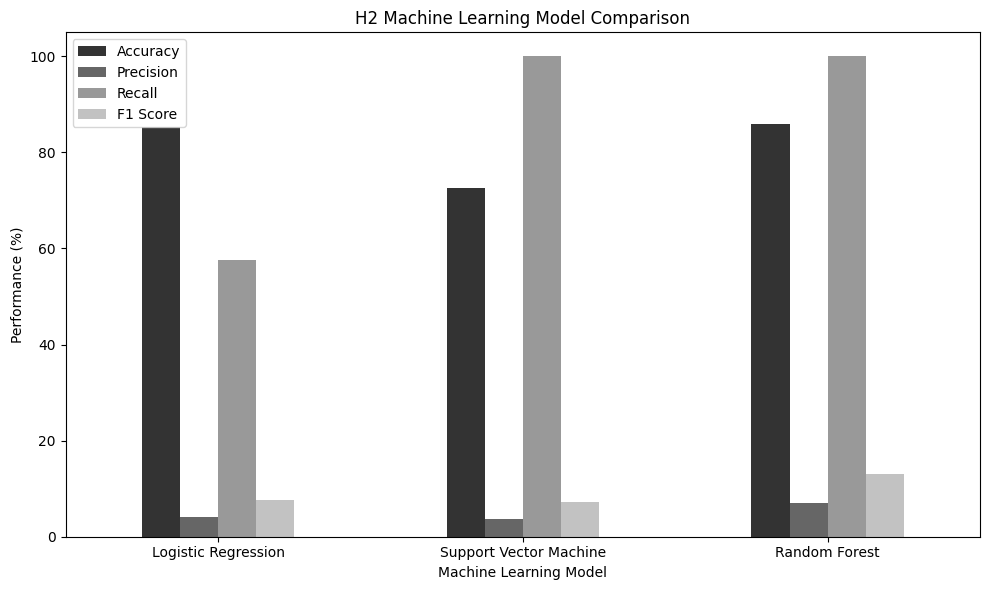

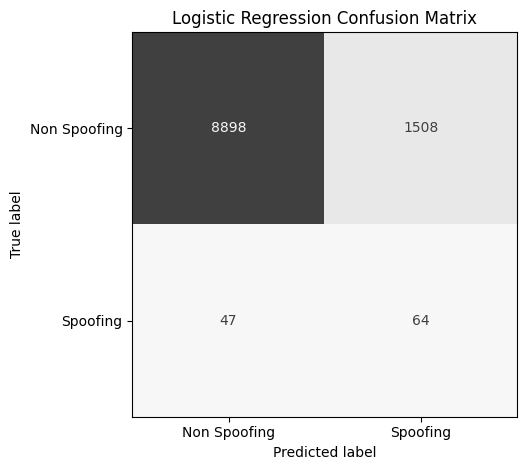

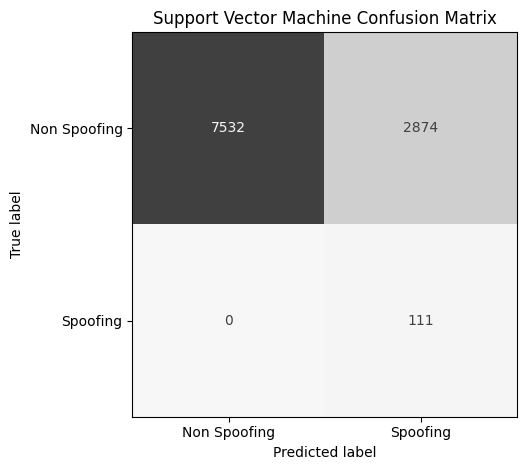

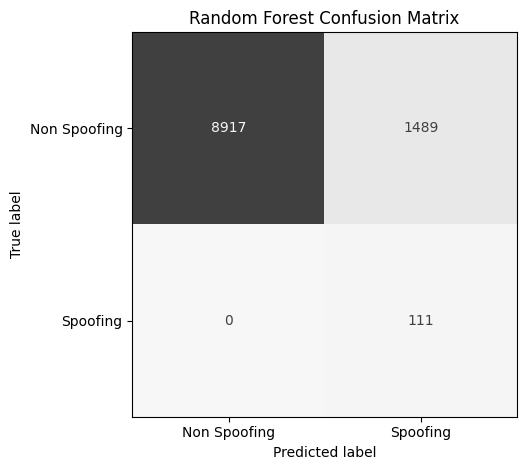


H2 result files saved successfully.


In [11]:
# Step 9: Validate and save the H2 results


# Load the libraries

import os
import matplotlib.pyplot as plt

from matplotlib.colors import LinearSegmentedColormap
from sklearn.metrics import ConfusionMatrixDisplay


# Identify the model with the highest accuracy

best_model = (
    h2_model_comparison
    .sort_values(
        "Accuracy",
        ascending=False
    )
    .iloc[0]
)


# Determine the H2 decision

if best_model["Model"] == "Random Forest":

    h2_decision = "Supported"

else:

    h2_decision = "Not Supported"


# Show the final H2 results

print("Final H2 Results")

print(
    "\nHighest accuracy model:",
    best_model["Model"]
)

print(
    "Highest accuracy:",
    round(
        best_model["Accuracy"] * 100,
        2
    ),
    "%"
)

print(
    "\nRandom Forest precision:",
    round(
        random_forest_results["Precision"] * 100,
        2
    ),
    "%"
)

print(
    "Random Forest recall:",
    round(
        random_forest_results["Recall"] * 100,
        2
    ),
    "%"
)

print(
    "Random Forest F1 score:",
    round(
        random_forest_results["F1 Score"] * 100,
        2
    ),
    "%"
)

print(
    "Random Forest false positives:",
    random_forest_results["False Positives"]
)

print(
    "Random Forest false negatives:",
    random_forest_results["False Negatives"]
)

print(
    "\nH2 Decision:",
    h2_decision
)


# Create the results folder

results_folder = (
    main_folder +
    "/08_H2_Results"
)


os.makedirs(
    results_folder,
    exist_ok=True
)


# Save the Logistic Regression results

pd.DataFrame(
    [logistic_results]
).to_csv(
    results_folder +
    "/h2_logistic_regression_results.csv",
    index=False
)


# Save the Support Vector Machine results

pd.DataFrame(
    [svm_results]
).to_csv(
    results_folder +
    "/h2_svm_results.csv",
    index=False
)


# Save the Random Forest results

pd.DataFrame(
    [random_forest_results]
).to_csv(
    results_folder +
    "/h2_random_forest_results.csv",
    index=False
)


# Save the model comparison table

h2_model_comparison.to_csv(
    results_folder +
    "/h2_model_comparison.csv",
    index=False
)


# Set the figure colors

comparison_colors = [
    "#333333",
    "#666666",
    "#999999",
    "#C2C2C2"
]


confusion_colors = LinearSegmentedColormap.from_list(
    "gray_scale",
    [
        "#F7F7F7",
        "#D9D9D9",
        "#969696",
        "#404040"
    ]
)


# Create the model comparison figure

comparison_figure = (
    h2_model_comparison[
        [
            "Model",
            "Accuracy",
            "Precision",
            "Recall",
            "F1 Score"
        ]
    ]
    .set_index("Model")
    * 100
)


comparison_figure.plot(
    kind="bar",
    figsize=(10, 6),
    color=comparison_colors
)


plt.title(
    "H2 Machine Learning Model Comparison"
)

plt.ylabel(
    "Performance (%)"
)

plt.xlabel(
    "Machine Learning Model"
)

plt.xticks(
    rotation=0
)

plt.ylim(
    0,
    105
)

plt.tight_layout()


plt.savefig(
    results_folder +
    "/h2_model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)


plt.show()

plt.close()


# Create the Logistic Regression confusion matrix

ConfusionMatrixDisplay.from_predictions(
    y_test,
    logistic_predictions,
    display_labels=[
        "Non Spoofing",
        "Spoofing"
    ],
    values_format="d",
    cmap=confusion_colors,
    colorbar=False
)


plt.title(
    "Logistic Regression Confusion Matrix"
)

plt.tight_layout()


plt.savefig(
    results_folder +
    "/h2_logistic_regression_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)


plt.show()

plt.close()


# Create the Support Vector Machine confusion matrix

ConfusionMatrixDisplay.from_predictions(
    y_test,
    svm_predictions,
    display_labels=[
        "Non Spoofing",
        "Spoofing"
    ],
    values_format="d",
    cmap=confusion_colors,
    colorbar=False
)


plt.title(
    "Support Vector Machine Confusion Matrix"
)

plt.tight_layout()


plt.savefig(
    results_folder +
    "/h2_svm_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)


plt.show()

plt.close()


# Create the Random Forest confusion matrix

ConfusionMatrixDisplay.from_predictions(
    y_test,
    random_forest_predictions,
    display_labels=[
        "Non Spoofing",
        "Spoofing"
    ],
    values_format="d",
    cmap=confusion_colors,
    colorbar=False
)


plt.title(
    "Random Forest Confusion Matrix"
)

plt.tight_layout()


plt.savefig(
    results_folder +
    "/h2_random_forest_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)


plt.show()

plt.close()


print(
    "\nH2 result files saved successfully."
)

## H2 Summary

The H2 comparison showed differences across Logistic Regression, Support Vector Machine, and Random Forest.

Random Forest produced the highest accuracy at 85.84 percent. Support Vector Machine and Random Forest both identified all 111 spoofed records in the testing data, while Logistic Regression identified 64.

Random Forest produced 1,489 false positives and no false negatives. Its precision was 6.94 percent, recall was 100 percent, and F1 score was 12.97 percent.

Based on the highest spoofing detection accuracy among the three models, the results support H2 within the simulated RFID baggage tracking environment.